<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m11-6-inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inference for the slope

So far we have described these 89 homes. Now we treat them as a sample and ask what they tell us about the relationship between size and price beyond this sample: how precisely we know the slope, and whether the relationship could be due to chance.

*Data: Ames housing data (De Cock, 2011, Journal of Statistics Education), single-family homes in the North Ames neighborhood sold under normal conditions in 2007. `area` is the above-ground living area in square feet, and `price` is the sale price in dollars.*

The same three steps as before: libraries, data, model.

In [1]:
# @title
import pandas as pd
import statsmodels.api as sm

homes = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
model = sm.formula.ols("price ~ area", data=homes).fit()

In [2]:
# @title Setup for the illustrations (colors and helper functions)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import scipy.stats as stats
from matplotlib.patches import FancyBboxPatch

PURPLE, GOLD, GRAY, LIGHT, SAND = "#510C76", "#B07A00", "#6E6E6E", "#C9B8D6", "#EFE3C2"
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#444444", "ytick.color": "#444444",
                     "axes.titlesize": 14, "legend.fontsize": 12})
DOLLARS = mtick.FuncFormatter(lambda v, p: "$0" if v == 0 else ("−" if v < 0 else "") + f"${abs(v)/1000:,.0f}K")


def fit(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - b1 * x.mean(), b1


def home_axes(ax, xlim=(700, 2400), ylim=(0, 290000)):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(DOLLARS)
    ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")


na = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
x, y = na.area.values.astype(float), na.price.values.astype(float)
b0, b1 = fit(x, y)
yhat = b0 + b1 * x
res = y - yhat
XS = np.linspace(700, 2400, 100)
n = len(x)
xbar = x.mean()
ssxx = np.sum((x - xbar) ** 2)
s = np.sqrt(np.sum(res ** 2) / (n - 2))


def box(ax, cx, cy, w, h, text, ec=PURPLE, fc="white", fs=13):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fs)

def arrow(ax, p, q, color=PURPLE):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))

plt.rcParams["figure.dpi"] = 110

## Another sample, another line

With a different set of homes we would get a different line. To see how much the line could move, we resampled the 89 homes 200 times (drawing homes at random with replacement) and fit a line to each resample. The slope varies around 64, roughly between 50 and 80.

Just as $\bar{x}$ has a sampling distribution, so does $b_1$. Its standard deviation is called the **standard error of the slope**, and the t test and the confidence interval are built on it.

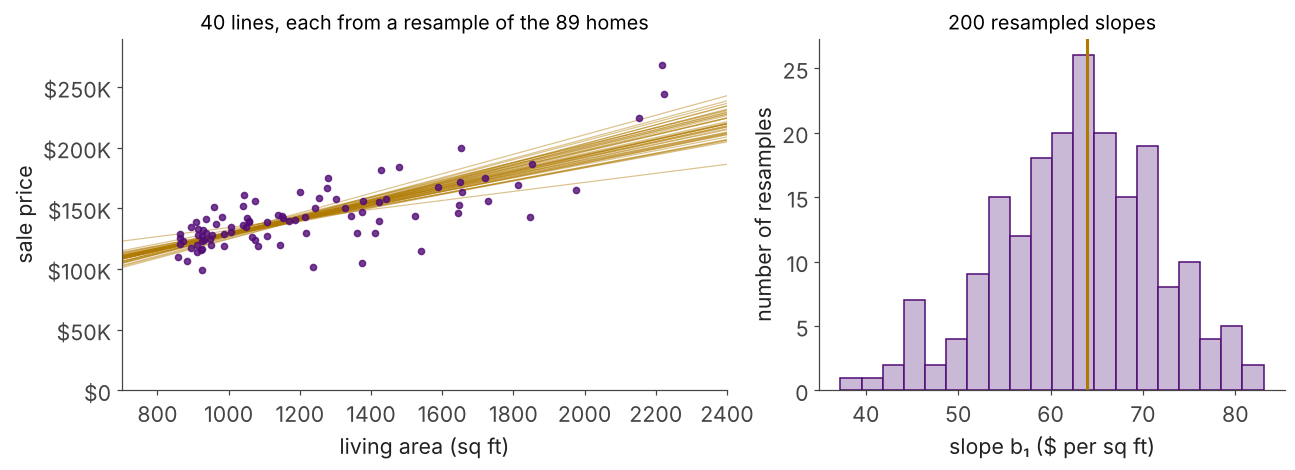

In [3]:
# @title Show the plotting code
# ---------------- 8. inference ----------------
rngb = np.random.default_rng(2007)
bs = []
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
for k in range(200):
    idx = rngb.integers(0, n, n)
    aa, bb = fit(x[idx], y[idx]); bs.append(bb)
    if k < 40:
        axs[0].plot(XS, aa + bb * XS, color=GOLD, lw=0.8, alpha=0.45)
axs[0].scatter(x, y, color=PURPLE, s=16, alpha=0.8, zorder=3)
home_axes(axs[0]); axs[0].set_title("40 lines, each from a resample of the 89 homes", fontsize=13)
axs[1].hist(bs, bins=20, color=LIGHT, edgecolor=PURPLE)
axs[1].axvline(b1, color=GOLD, lw=2)
axs[1].set_xlabel("slope b₁ ($ per sq ft)"); axs[1].set_ylabel("number of resamples")
axs[1].set_title("200 resampled slopes", fontsize=13)
fig.tight_layout(); plt.show()  # f29_resampled_lines.png

## The standard error of the slope

$$s_{b_1} = \frac{s_e}{\sqrt{\sum (x_i - \bar{x})^2}} = \frac{17{,}941}{\sqrt{9{,}915{,}326}} = 5.698$$

The slope is estimated more precisely when the homes scatter less around the line (small $s_e$) and when the data cover a wide range of sizes (large $\sum (x_i - \bar{x})^2$). More homes help through the second part: every additional home adds a term to the sum.

In the summary this is the `std err` in the `area` row.

In [4]:
# @title
model.bse

Intercept    7223.617491
area            5.697638
dtype: float64

## Testing the slope

If $\beta_1$ were zero, the mean price would not change with living area, and the line would be no help in predicting price.

$$H_0\!: \beta_1 = 0 \qquad H_a\!: \beta_1 \ne 0$$

$$t = \frac{b_1}{s_{b_1}} = \frac{63.94}{5.698} = 11.22, \qquad df = n - 2 = 87$$

The p-value is the probability of a slope this far from zero, in either direction, if $\beta_1$ were really zero. Here it is about $1.3 \times 10^{-18}$: the data provide very strong evidence that sale price is linearly related to living area among North Ames homes.

In the summary these are the `t` and `P>|t|` columns. Python prints very small p-values as 0.000, which means less than 0.0005, not zero.

In [5]:
# @title
print(model.tvalues)
print(model.pvalues)

Intercept     9.048672
area         11.223062
dtype: float64
Intercept    3.570249e-14
area         1.349076e-18
dtype: float64


## Confidence interval for the slope

$$b_1 \pm t_{0.025}\, s_{b_1} = 63.94 \pm 1.988(5.698) = [52.62,\ 75.27]$$

*We are 95% confident that, among North Ames homes, each additional square foot of living area is associated with \$53 to \$75 more in sale price, on average.*

The interval says more than the test: not only that the slope is not zero, but how large it plausibly is. In the summary it is the `[0.025` and `0.975]` columns.

In [6]:
# @title
model.conf_int(alpha=0.05)

,0,1
Intercept,51006.425984,79721.869880
area,52.620272,75.269617


The `Intercept` row has its own standard error, t, p-value, and interval, testing $\beta_0 = 0$. Here that test answers no useful question: a home of 0 square feet is far outside the data.

## Three tests, one p-value

With one explanatory variable, three tests ask the same question and give the same p-value: the t test for the slope, the F test at the top of the summary, and the test of zero correlation. $F = t^2$. With several explanatory variables, they answer different questions.

| Test | Null hypothesis | Statistic | p-value |
|---|---|---|---|
| t test for the slope | $\beta_1 = 0$ | $t = 11.22$ | $1.3 \times 10^{-18}$ |
| F test (`F-statistic`, `Prob (F-statistic)`) | $\beta_1 = 0$ | $F = t^2 = 125.96$ | $1.3 \times 10^{-18}$ |
| Test of the correlation | $\rho = 0$ | $r = 0.77$ | $1.3 \times 10^{-18}$ |

In [7]:
# @title
from scipy import stats

r, p_corr = stats.pearsonr(homes["area"], homes["price"])
print(f"t test:       t = {model.tvalues['area']:.2f},  p = {model.pvalues['area']:.3g}")
print(f"F test:       F = {model.fvalue:.2f},  p = {model.f_pvalue:.3g}")
print(f"correlation:  r = {r:.3f},  p = {p_corr:.3g}")

t test:       t = 11.22,  p = 1.35e-18
F test:       F = 125.96,  p = 1.35e-18
correlation:  r = 0.769,  p = 1.35e-18


## The whole summary, now readable

With inference added, every line of the summary we use in this course has a meaning. The `Adj. R-squared` waits for multiple regression.

In [8]:
# @title
model.summary(slim=True)

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.591
Model:                            OLS   Adj. R-squared:                  0.587
No. Observations:                  89   F-statistic:                     126.0
Covariance Type:            nonrobust   Prob (F-statistic):           1.35e-18
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   6.536e+04   7223.617      9.049      0.000     5.1e+04    7.97e+04
area          63.9449      5.698     11.223      0.000      52.620      75.270
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.82e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## The same numbers in Excel

Excel's Analysis ToolPak (Data > Data Analysis > Regression) reports the same numbers with different labels: Multiple R is $|r|$, Standard Error in the top table is $s_e$, the ANOVA rows are Regression and Residual, and Significance F is the p-value of the F test.

| Regression Statistics | |
|---|---:|
| Multiple R | 0.769069 |
| R Square | 0.591467 |
| Adjusted R Square | 0.586771 |
| Standard Error | 17941.07 |
| Observations | 89 |

| | df | SS | MS | F | Significance F |
|---|---:|---:|---:|---:|---:|
| Regression | 1 | 4.05433E+10 | 4.05433E+10 | 125.9571 | 1.35E-18 |
| Residual | 87 | 2.80037E+10 | 321882009 | | |
| Total | 88 | 6.85471E+10 | | | |

| | Coefficients | Standard Error | t Stat | P-value | Lower 95% | Upper 95% |
|---|---:|---:|---:|---:|---:|---:|
| Intercept | 65364.15 | 7223.617 | 9.048672 | 3.57E-14 | 51006.43 | 79721.87 |
| area | 63.94494 | 5.697638 | 11.22306 | 1.35E-18 | 52.62027 | 75.26962 |

## When can we trust these numbers?

The standard error, the p-value, and the interval are only as good as the assumptions behind them. Independence comes first, and it depends on how the data were collected, not on any plot. This is why we used one neighborhood and one year. Homes in the same neighborhood share a location that the line does not include, and homes sold in the same months share market conditions. If we mixed neighborhoods, whole groups of homes would sit above or below the line, their errors would not be independent, and the standard errors would come out too small.

The other assumptions we check with residual plots. These synthetic examples show what violations look like:

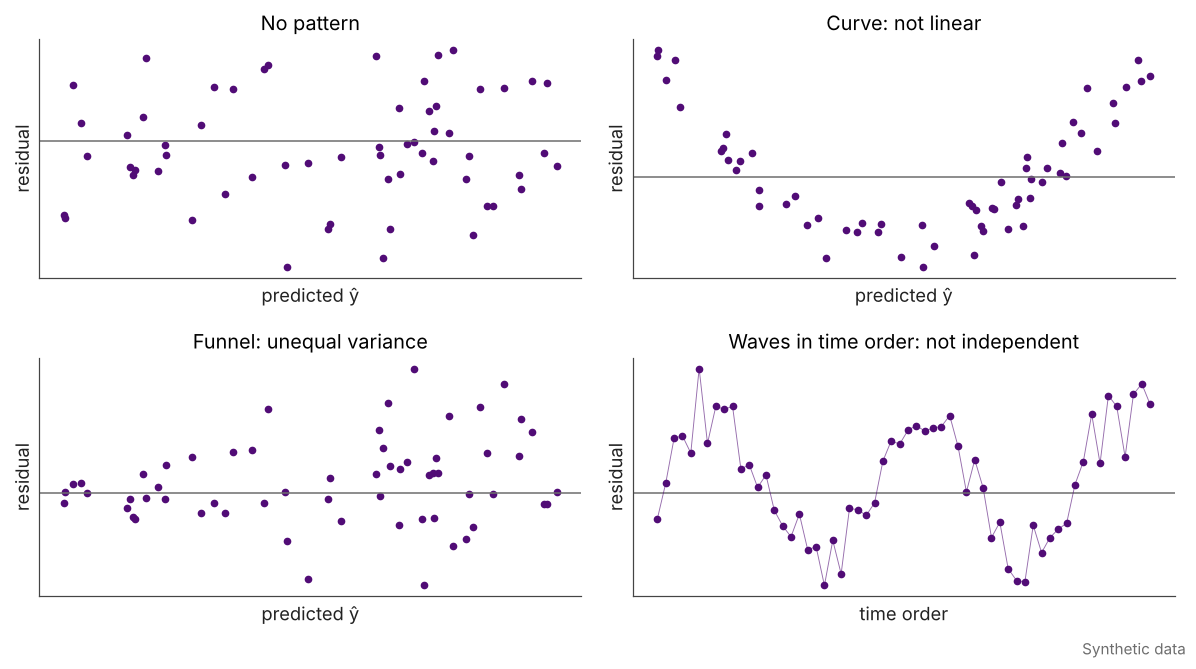

In [9]:
# @title Show the plotting code
rng14 = np.random.default_rng(14); m = 60; fv = np.sort(rng14.uniform(0, 10, m))
pats = [("No pattern", rng14.normal(0, 1, m), "predicted ŷ"),
        ("Curve: not linear", 0.25 * (fv - 5) ** 2 - 2 + rng14.normal(0, 0.6, m), "predicted ŷ"),
        ("Funnel: unequal variance", rng14.normal(0, 0.15 + 0.3 * fv, m), "predicted ŷ"),
        ("Waves in time order: not independent", 1.6 * np.sin(np.arange(m) / 4) + rng14.normal(0, 0.5, m), "time order")]
fig, axs = plt.subplots(2, 2, figsize=(11, 6))
for ax, (t, e_, xl_) in zip(axs.ravel(), pats):
    xv = np.arange(1, m + 1) if "time" in xl_ else fv
    ax.axhline(0, color=GRAY, lw=1); ax.scatter(xv, e_, color=PURPLE, s=16)
    if "time" in xl_: ax.plot(xv, e_, color=PURPLE, lw=0.6, alpha=0.6)
    ax.set_title(t, fontsize=13); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(xl_, fontsize=12); ax.set_ylabel("residual", fontsize=12)
fig.text(0.99, -0.01, "Synthetic data", ha="right", fontsize=10, color=GRAY)
fig.tight_layout(); plt.show()  # f32_residual_patterns.png

When we read the North Ames diagnostic plots, we saw no serious problem: no funnel, no time pattern, and residuals close to normal apart from a few homes at the ends. With 89 homes, the central limit theorem covers small departures from normality.

Two more limits hold even when every assumption is met. A small p-value does not mean the relationship is causal, and it does not mean the slope is large enough to matter; for that, look at $b_1$ and its confidence interval.